# EDA: `raw_seat_reviews`

One notebook per raw Skytrax table (index in `eda.ipynb`). It follows `eda_template.ipynb` section by section: big picture, get the data, clean, check quality, explore, summarise.

**Role of this table:** Fact table of seat reviews, one row per review. Joins to `raw_airlines` on `airline_id`.

**How to use**
1. Run the notebook from the `notebooks/` folder (the data path is relative to the repo root).
2. Run all cells once, top to bottom. Every section adapts to the columns it finds.
3. Read section 7 (Summary of Findings): it was drafted from the data and is waiting for your review.

**Read-only:** the CSV in `data/` is only read. Cleaning below happens on an in-memory copy (`df`); the real cleaning rules are written later in dbt staging.

## Table of Contents

- [0. Setup](#sec-0)
  - [0.1 Imports](#sec-0-1)
  - [0.2 Config](#sec-0-2)
  - [0.3 Plot style](#sec-0-3)
  - [0.4 Helpers](#sec-0-4)
- [1. Look at the Big Picture](#sec-1)
  - [1.1 Frame the Problem](#sec-1-1)
  - [1.2 Questions & Hypotheses](#sec-1-2)
  - [1.3 Performance Measure (for later modelling)](#sec-1-3)
  - [1.4 Check the Assumptions](#sec-1-4)
- [2. Get the Data](#sec-2)
  - [2.1 Data Dictionary](#sec-2-1)
- [3. Data Cleaning (General)](#sec-3)
  - [3.1 Format Column Names](#sec-3-1)
  - [3.2 Format Data Body](#sec-3-2)
  - [3.3 Format Datatypes](#sec-3-3)
  - [3.4 Duplicates](#sec-3-4)
  - [3.5 Domain Sanity Checks](#sec-3-5)
- [4. Data Quality](#sec-4)
  - [4.1 Missing Values](#sec-4-1)
  - [4.2 Outliers](#sec-4-2)
- [5. Attribute Combination](#sec-5)
- [6. EDA](#sec-6)
  - [6.0 Classify Attributes](#sec-6-0)
  - [6.1 Univariate](#sec-6-1)
  - [6.2 Bivariate](#sec-6-2)
  - [6.3 Multivariate](#sec-6-3)
- [7. Summary of Findings](#sec-7)
- [8. Hand-off to Modelling](#sec-8)

# 0. Setup<a id="sec-0"></a>

## 0.1 Imports<a id="sec-0-1"></a>

In [1]:
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", "{:,.2f}".format)

## 0.2 Config<a id="sec-0-2"></a>

Everything dataset-specific lives here. Column names are the **snake_case** names produced in section 3.1.

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()

TABLE = "seat_reviews"            # name of the file in data/
DATA_PATH = ROOT / "data" / f"{TABLE}.csv"
TARGET = "recommended"        # yes/no: the business question is what goes with a recommendation
PROBLEM_TYPE = "classification"   # nothing is predicted: this only switches on the target views of the template
ID_COLS = ['review_id']       # identifiers: excluded from analysis
CAT_COLS = ['airline_id']     # force these to categorical; None = auto-detect
CAT_MAX_UNIQUE = 15           # numeric columns with <= this many values are treated as discrete
HIGH_CORR = 0.8               # |r| above this is flagged as multicollinearity
TOP_N_CATEGORIES = 10         # categories shown per bar chart

SAVE_FIGS = False             # True writes every figure to FIG_DIR
FIG_DIR = ROOT / "reports" / "figures"
RANDOM_STATE = 42

## 0.3 Plot style<a id="sec-0-3"></a>

One consistent look: blue for single-series charts, a fixed categorical order for
hue splits (max 3 groups per chart), and a blue ↔ gray ↔ red diverging map for correlations.

In [3]:
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
MAIN = PALETTE[0]
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#184f95", "#86b6ef", "#f0efec", "#f19a99", "#b52f2e"])

sns.set_theme(
    style="whitegrid",
    palette=PALETTE,
    rc={
        "axes.edgecolor": "#c3c2b7",
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.labelcolor": "#52514e",
        "grid.color": "#ecebe7",
        "xtick.color": "#52514e",
        "ytick.color": "#52514e",
        "lines.linewidth": 2,
        "figure.dpi": 100,
    },
)

## 0.4 Helpers<a id="sec-0-4"></a>

In [4]:
def to_snake_case(df):
    """CamelCase / spaces / dashes -> snake_case column names."""
    df = df.copy()
    df.columns = (
        df.columns.str.strip()
        .str.replace(r"(?<=[a-z0-9])(?=[A-Z])", "_", regex=True)
        .str.replace(r"[\s\-/]+", "_", regex=True)
        .str.lower()
    )
    return df


def save_fig(fig, name):
    if SAVE_FIGS and name:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"{name}.png", dpi=110, bbox_inches="tight")


def plot_grid(columns, plot_fn, ncols=4, height=3.0, title=None, name=None, shared_legend=False):
    """Draw plot_fn(col, ax) for every column in a grid of subplots.

    shared_legend=True replaces per-panel legends with one legend above the grid.
    """
    columns = list(columns)
    if not columns:
        print("Nothing to plot.")
        return
    nrows = math.ceil(len(columns) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, height * nrows), squeeze=False)
    axes = axes.ravel()
    for ax, col in zip(axes, columns):
        plot_fn(col, ax)
        ax.set_title(col)
    for ax in axes[len(columns):]:
        ax.axis("off")
    fig.tight_layout()
    legend = axes[0].get_legend()
    if shared_legend and legend:
        handles, labels = legend.legend_handles, [t.get_text() for t in legend.get_texts()]
        fig.legend(handles, labels, title=legend.get_title().get_text(), loc="lower center",
                   bbox_to_anchor=(0.5, 1.0), ncol=len(labels), frameon=False)
        for ax in axes:
            if ax.get_legend():
                ax.get_legend().remove()
    if title:
        fig.suptitle(title, fontsize=13, fontweight="bold", y=1.0 + (0.7 / fig.get_figheight() if shared_legend and legend else 0))
    save_fig(fig, name)
    plt.show()


def missing_report(df):
    """Count and % of nulls per column (only columns with nulls)."""
    report = pd.DataFrame({
        "n_missing": df.isna().sum(),
        "pct_missing": df.isna().mean() * 100,
        "dtype": df.dtypes.astype(str),
    })
    return report[report.n_missing > 0].sort_values("n_missing", ascending=False)


def outlier_report(df, columns, k=1.5):
    """IQR-based outlier counts. Detection only - nothing is removed."""
    rows = []
    for col in columns:
        s = df[col].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - k * iqr, q3 + k * iqr
        n_out = int(((s < lo) | (s > hi)).sum())
        rows.append({"column": col, "lower": lo, "upper": hi, "min": s.min(), "max": s.max(),
                     "n_outliers": n_out, "pct_outliers": 100 * n_out / len(s)})
    return pd.DataFrame(rows).set_index("column").sort_values("n_outliers", ascending=False)


def classify_columns(df, target=None, id_cols=(), cat_cols=None, cat_max_unique=15):
    """Split columns into constant / binary / categorical / discrete / continuous."""
    groups = {"constant": [], "binary": [], "categorical": [], "discrete": [], "continuous": []}
    forced_cat = set(cat_cols or [])
    for col in df.columns:
        if col in id_cols or col == target:
            continue
        n = df[col].nunique(dropna=True)
        if n <= 1:
            groups["constant"].append(col)
        elif n == 2:
            groups["binary"].append(col)
        elif col in forced_cat or not pd.api.types.is_numeric_dtype(df[col]):
            groups["categorical"].append(col)
        elif n <= cat_max_unique:
            groups["discrete"].append(col)
        else:
            groups["continuous"].append(col)
    return groups

# 1. Look at the Big Picture<a id="sec-1"></a>

## 1.1 Frame the Problem<a id="sec-1-1"></a>

Answered before touching the data. Business context: the stakeholder is the Head of Customer Experience of a mid-size full-service airline, who decides how to split the yearly budget for improving the customer experience.

* **What is the business objective?**
  Decide which seat improvements to fund first in economy (legroom, recline, width, aisle space, storage, power, screen).
* **How will the output be used?**
  The Head of Customer Experience uses it to rank seat aspects and to see how the airline compares with peers on the aircraft it flies.
* **What does the target look like?** (regression / classification / none)
  `recommended` (yes/no), so a classification-style view. Nothing is predicted: we only look at which aspects go together with a customer recommending the airline.
* **What would a useful result be?**
  A ranked list of seat aspects by how strongly they go with `recommended`, with the weakest aspects in economy.

Main question (all review tables): *which service aspect goes together most with customers recommending the airline, and where is the airline weaker than its peers?*

## 1.2 Questions & Hypotheses<a id="sec-1-2"></a>

The questions this EDA must answer. Each one maps to a section below. Q-numbers follow the business question list; `D1` is the data-readiness check that comes first.

| # | Question | Answered in |
|---|---|---|
| D1 | Can we trust the data enough to answer (formats, placeholders, wrong-column values, duplicates)? | 3, 4 |
| Q1 | In economy, which seat aspect scores lowest? | 6.1, 6.3.1 |
| Q2 | Which seat aspect goes together most with `recommended`? | 6.2 |
| Q3 | How many airlines have at least 100 seat reviews (enough to be a peer)? | 6.3.1 |
| Q4 | Are premium (lie-flat) ratings empty by design, and are some ratings redundant? | 4.1, 6.3 |

## 1.3 Performance Measure (for later modelling)<a id="sec-1-3"></a>

Pick now so the EDA looks at the right things (e.g. skewed target → consider RMSLE / log target).

* **Regression:** RMSE, MAE, MAPE, RMSLE, adjusted R²
* **Classification:** ROC-AUC, PR-AUC, F1, precision/recall, confusion matrix (check class balance in 6.1)

*Here there is no model, so the "performance measure" is a business one: the recommend rate and the mean-score gap per aspect (built later in the marts).*

## 1.4 Check the Assumptions<a id="sec-1-4"></a>

To confirm with the data owner / stakeholder.

* `review_id` is the primary key; one row = one seat review.
* `date_flown` is the first day of the flight month, not the exact day.
* Premium ratings (bed width, privacy, ...) only exist for lie-flat seats, so they are empty by design.
* Seat reviews are few (about 3,400), so groups by aircraft or layout get small quickly.
* Reviews are voluntary opinions posted on Skytrax, not a random survey: results describe people who write reviews.
* `recommended` measures how appealing an airline is, not whether the ticket was bought. We say "goes with", never "causes".
* Scores differ strongly by region and nationality, so only compare like with like (same cabin, same region).

# 2. Get the Data<a id="sec-2"></a>

In [5]:
raw = pd.read_csv(DATA_PATH)   # the CSV is only read, never changed
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")

3,766 rows x 26 columns


In [6]:
# Take a look at the top 5 rows
raw.head()

,review_id,airline_id,type_of_traveller,seat_type,aircraft_type,seat_layout,verify,date_submitted,date_flown,customer_name,nationality,seat_legroom,seat_recline,seat_width,aisle_space,seat_storage,power_supply,viewing_tv_screen,sleep_comfort,sitting_comfort,seat_bed_width,seat_bed_length,seat_privacy,recommended,review,updated_at
0,1,17,Couple Leisure,Economy Class,Boeing 737-800,3x3,True,2023-08-26,2023-08-01,Carol Costa 29,Canada,1.00,1.00,1.00,1.00,1.00,2.00,2.00,NaN,NaN,NaN,NaN,NaN,False,"The seats on the way to Cancun from Mexico City were cramped, and the layout...",2026-06-20 12:45:41
1,2,17,Solo Leisure,Economy Class,Boeing 737-800,3x3,True,2022-03-15,2022-03-01,Laura Patel 28,United States,3.00,3.00,3.00,3.00,2.00,NaN,2.00,NaN,NaN,NaN,NaN,NaN,False,"Seats are hard as a rock, slanting downwards, permanent butt formations, but...",2026-06-20 12:45:41
2,3,17,Business,Economy Class,Boeing 787-9,3x3x3,True,2019-06-26,2019-06-01,Mary Adams 31,Spain,5.00,5.00,2.00,3.00,5.00,4.00,5.00,NaN,NaN,NaN,NaN,NaN,True,It was my first experience on a 9-abreast Dreamliner after having travelled ...,2026-06-20 12:45:41
3,4,17,Family Leisure,Premium Economy,Boeing 737-800,3x3,True,2018-09-29,2018-09-01,Michael Smith 4,Mexico,5.00,5.00,5.00,5.00,5.00,5.00,5.00,NaN,NaN,NaN,NaN,NaN,True,"Good leg space and recline on AM Plus seats, an approximate 5-hour flight an...",2026-06-20 12:45:41
4,5,17,Couple Leisure,Economy Class,Boeing 737-800,3x3,True,2018-09-10,2018-09-01,Christopher Smith 3,Mexico,5.00,5.00,5.00,5.00,5.00,5.00,5.00,NaN,NaN,NaN,NaN,NaN,True,"Main Cabin Seat 24A, window. Good recline, good length and good width. I fel...",2026-06-20 12:45:41


In [7]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 3766 entries, 0 to 3765
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          3766 non-null   int64  
 1   airline_id         3766 non-null   int64  
 2   type_of_traveller  2465 non-null   str    
 3   seat_type          3763 non-null   str    
 4   aircraft_type      3519 non-null   str    
 5   seat_layout        3762 non-null   str    
 6   verify             3766 non-null   bool   
 7   date_submitted     3766 non-null   str    
 8   date_flown         2460 non-null   str    
 9   customer_name      3764 non-null   str    
 10  nationality        3764 non-null   str    
 11  seat_legroom       3543 non-null   float64
 12  seat_recline       3542 non-null   float64
 13  seat_width         3543 non-null   float64
 14  aisle_space        3542 non-null   float64
 15  seat_storage       2448 non-null   float64
 16  power_supply       1384 non-null   

In [8]:
raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
review_id,"3,766.00",NaN,NaN,NaN,"1,883.50","1,087.29",1.00,942.25,"1,883.50","2,824.75","3,766.00"
airline_id,"3,766.00",NaN,NaN,NaN,298.74,170.01,4.00,151.00,300.00,419.00,594.00
type_of_traveller,2465,5,Solo Leisure,784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seat_type,3763,5,Economy Class,2965,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aircraft_type,3519,63,Airbus A330,387,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seat_layout,3762,78,3x3,895,NaN,NaN,NaN,NaN,NaN,NaN,NaN
verify,3766,2,False,2844,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_submitted,3766,1442,2014-11-19,90,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_flown,2460,137,2015-08-01,77,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_name,3764,3029,Ronald Mitchell 8,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2.1 Data Dictionary<a id="sec-2-1"></a>

One row per column: what it means, its type, how many distinct values, and an example. The meanings are inferred from the column names and the data.

In [9]:
# Meaning of each column (from the column name and the data; correct them if you know better)
MEANINGS = {
    "review_id": "Review id (primary key)",
    "verify": "Verified review",
    "date_submitted": "Date the review was posted",
    "customer_name": "Reviewer name (ends with an anonymisation number)",
    "nationality": "Reviewer country",
    "recommended": "Reviewer recommends it",
    "review": "Free-text review",
    "updated_at": "Load time",
    "airline_id": "Airline reviewed, joins to `raw_airlines`",
    "type_of_traveller": "Trip type (Solo Leisure, Couple Leisure, Family Leisure, Business, ...)",
    "seat_type": "Cabin class (Economy Class, Business Class, ...)",
    "aircraft_type": "Aircraft model flown",
    "seat_layout": "Seat configuration such as 3x3x3",
    "date_flown": "Month of the flight (first day of month)",
    "seat_legroom": "Core rating 1 to 5",
    "seat_recline": "Core rating 1 to 5",
    "seat_width": "Core rating 1 to 5",
    "aisle_space": "Core rating 1 to 5",
    "seat_storage": "Optional rating 1 to 5",
    "power_supply": "Optional rating 1 to 5",
    "viewing_tv_screen": "Optional rating 1 to 5",
    "sleep_comfort": "Premium (lie-flat) rating 1 to 5",
    "sitting_comfort": "Premium (lie-flat) rating 1 to 5",
    "seat_bed_width": "Premium (lie-flat) rating 1 to 5",
    "seat_bed_length": "Premium (lie-flat) rating 1 to 5",
    "seat_privacy": "Premium (lie-flat) rating 1 to 5",
}

data_dictionary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
    "example": raw.iloc[0],
    "meaning": pd.Series(MEANINGS),
}).reindex(raw.columns)
data_dictionary

,dtype,n_unique,example,meaning
review_id,int64,3766,1,Review id (primary key)
airline_id,int64,205,17,"Airline reviewed, joins to `raw_airlines`"
type_of_traveller,str,5,Couple Leisure,"Trip type (Solo Leisure, Couple Leisure, Family Leisure, Business, ...)"
seat_type,str,5,Economy Class,"Cabin class (Economy Class, Business Class, ...)"
aircraft_type,str,63,Boeing 737-800,Aircraft model flown
seat_layout,str,78,3x3,Seat configuration such as 3x3x3
verify,bool,2,True,Verified review
date_submitted,str,1442,2023-08-26,Date the review was posted
date_flown,str,137,2023-08-01,Month of the flight (first day of month)
customer_name,str,3029,Carol Costa 29,Reviewer name (ends with an anonymisation number)


# 3. Data Cleaning (General)<a id="sec-3"></a>

Cleaning that is safe to do on the **whole** dataset (no information from the target or test set is used).

## 3.1 Format Column Names<a id="sec-3-1"></a>

In [10]:
df = to_snake_case(raw)
df.columns.tolist()

['review_id',
 'airline_id',
 'type_of_traveller',
 'seat_type',
 'aircraft_type',
 'seat_layout',
 'verify',
 'date_submitted',
 'date_flown',
 'customer_name',
 'nationality',
 'seat_legroom',
 'seat_recline',
 'seat_width',
 'aisle_space',
 'seat_storage',
 'power_supply',
 'viewing_tv_screen',
 'sleep_comfort',
 'sitting_comfort',
 'seat_bed_width',
 'seat_bed_length',
 'seat_privacy',
 'recommended',
 'review',
 'updated_at']

In [11]:
# Manual renames, if any
# df = df.rename(columns={"unnamed:_0": "id"})

## 3.2 Format Data Body<a id="sec-3-2"></a>

Trim whitespace in text columns, then pull structured fields out of free-text columns.

In [12]:
text_cols = df.select_dtypes(include=["object", "string"]).columns
df[text_cols] = df[text_cols].apply(lambda s: s.str.strip())
for col in text_cols:
    print(f"{col}: {df[col].nunique()} unique -> {[str(v)[:40] for v in df[col].unique()[:8]]}")

type_of_traveller: 5 unique -> ['Couple Leisure', 'Solo Leisure', 'Business', 'Family Leisure', 'nan', 'Leisure']
seat_type: 5 unique -> ['Economy Class', 'Premium Economy', 'Business Class', 'First Class', 'World Traveller Plus', 'nan']
aircraft_type: 63 unique -> ['Boeing 737-800', 'Boeing 787-9', 'Boeing 787-8', 'Boeing 787-800', 'Boeing 737', 'nan', 'Airbus A321', 'Airbus A320']
seat_layout: 78 unique -> ['3x3', '3x3x3', '2x3', '2x4x2', '2-4-2', '2x3x2', '2x5x2', '2x2']
date_submitted: 1442 unique -> ['2023-08-26', '2022-03-15', '2019-06-26', '2018-09-29', '2018-09-10', '2018-09-09', '2017-08-10', '2016-09-08']
date_flown: 137 unique -> ['2023-08-01', '2022-03-01', '2019-06-01', '2018-09-01', '2017-08-01', '2016-08-01', '2015-12-01', '2019-08-01']
customer_name: 3029 unique -> ['Carol Costa 29', 'Laura Patel 28', 'Mary Adams 31', 'Michael Smith 4', 'Christopher Smith 3', 'Ingrid Hernandez 22', 'Anthony Perez 16', 'Ingrid Mitchell 15']
nationality: 97 unique -> ['Canada', 'United St

`customer_name` ends with an anonymisation number (e.g. `Joshua Torres 6`), which is not part of a real name. Strip it so the same person is written the same way.

In [13]:
has_suffix = df["customer_name"].str.contains(r"\s\d+$", na=False)
print(f"{has_suffix.sum():,} of {len(df):,} names end with a number")
df["customer_name"] = df["customer_name"].str.replace(r"\s+\d+$", "", regex=True)
pd.DataFrame({"before": raw["customer_name"], "after": df["customer_name"]}).loc[has_suffix].head(5)

3,635 of 3,766 names end with a number


,before,after
0,Carol Costa 29,Carol Costa
1,Laura Patel 28,Laura Patel
2,Mary Adams 31,Mary Adams
3,Michael Smith 4,Michael Smith
4,Christopher Smith 3,Christopher Smith


## 3.3 Format Datatypes<a id="sec-3-3"></a>

Check every column has the right type: dates → `datetime64`, flags → `int`/`bool`, labels → `category`.

In [14]:
df.dtypes.value_counts()

float64    12
str        10
int64       2
bool        2
Name: count, dtype: int64

In [15]:
# Dates must be datetime, flags must be nullable booleans (True / False / missing)
for col in [c for c in df.columns if c.startswith("date_") or c == "updated_at"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")
for col in [c for c in ["verify", "recommended"] if c in df.columns]:
    df[col] = df[col].astype("boolean")
df.dtypes.value_counts()

float64           12
str                7
datetime64[us]     3
int64              2
boolean            2
Name: count, dtype: int64

## 3.4 Duplicates<a id="sec-3-4"></a>

In [16]:
analysis_cols = [c for c in df.columns if c not in ID_COLS]
n_exact = df.duplicated().sum()
n_ignoring_id = df.duplicated(subset=analysis_cols).sum()
print(f"Exact duplicate rows:            {n_exact}")
print(f"Duplicates ignoring ID columns:  {n_ignoring_id}")
df[df.duplicated(subset=analysis_cols, keep=False)]

Exact duplicate rows:            0
Duplicates ignoring ID columns:  3


,review_id,airline_id,type_of_traveller,seat_type,aircraft_type,seat_layout,verify,date_submitted,date_flown,customer_name,nationality,seat_legroom,seat_recline,seat_width,aisle_space,seat_storage,power_supply,viewing_tv_screen,sleep_comfort,sitting_comfort,seat_bed_width,seat_bed_length,seat_privacy,recommended,review,updated_at
566,567,115,NaN,Economy Class,NaN,3x4x3,False,1970-01-01,NaT,Eric Kim,Switzerland,1.00,2.00,2.00,1.00,NaN,NaN,3.00,NaN,NaN,NaN,NaN,NaN,False,Definitely the worst flights ever in Economy class. Uncomfortable seats poor...,2026-06-20 12:45:41
567,568,115,NaN,Economy Class,Boeing 777,2x3x2,False,1970-01-01,NaT,Amanda Lopez,Austria,1.00,1.00,1.00,1.00,NaN,NaN,3.00,NaN,NaN,NaN,NaN,NaN,False,I travel a lot and this was the worst experience on any long haul flight in ...,2026-06-20 12:45:41
568,569,115,NaN,Economy Class,NaN,2x3x2,False,1970-01-01,NaT,Ashley Walker,Canada,2.00,2.00,3.00,2.00,NaN,NaN,1.00,NaN,NaN,NaN,NaN,NaN,False,Completely unacceptable for a long-haul flight. Seats do not recline much an...,2026-06-20 12:45:41
569,570,115,NaN,Economy Class,NaN,3x4x3,False,1970-01-01,NaT,Eric Kim,Switzerland,1.00,2.00,2.00,1.00,NaN,NaN,3.00,NaN,NaN,NaN,NaN,NaN,False,Definitely the worst flights ever in Economy class. Uncomfortable seats poor...,2026-06-20 12:45:41
570,571,115,NaN,Economy Class,Boeing 777,2x3x2,False,1970-01-01,NaT,Amanda Lopez,Austria,1.00,1.00,1.00,1.00,NaN,NaN,3.00,NaN,NaN,NaN,NaN,NaN,False,I travel a lot and this was the worst experience on any long haul flight in ...,2026-06-20 12:45:41
571,572,115,NaN,Economy Class,NaN,2x3x2,False,1970-01-01,NaT,Ashley Walker,Canada,2.00,2.00,3.00,2.00,NaN,NaN,1.00,NaN,NaN,NaN,NaN,NaN,False,Completely unacceptable for a long-haul flight. Seats do not recline much an...,2026-06-20 12:45:41


In [17]:
# Decide: drop or keep? Duplicates ignoring the ID usually mean the same record was loaded twice.
df = df.drop_duplicates(subset=analysis_cols).reset_index(drop=True)
print(f"{len(df):,} rows after de-duplication")

3,763 rows after de-duplication


## 3.5 Domain Sanity Checks<a id="sec-3-5"></a>

Values that are *possible* to store but *impossible* in reality (placeholder dates, wrong-column values, leftovers).
These are not statistical outliers; they are data-entry or scraping errors. Wrong dates are set to missing here, like the staging model will do.

In [18]:
# Dates: 1970-01-01 is a placeholder for "no date", not a real date -> set to missing
date_cols = [c for c in df.select_dtypes(include="datetime").columns if c != "updated_at"]
for col in date_cols:
    n_placeholder = (df[col] < "1990-01-01").sum()
    print(f"{col}: {n_placeholder} placeholder dates (before 1990)")
    df.loc[df[col] < "1990-01-01", col] = pd.NaT

# The trip date can never be later than the day the review was written
visit_col = next((c for c in ["date_flown", "date_visit"] if c in df.columns), None)
if visit_col:
    wrong_order = df[visit_col] > df["date_submitted"]
    print(f"{visit_col} later than date_submitted: {wrong_order.sum()} rows (set to missing)")
    display(df.loc[wrong_order, ["review_id", "date_submitted", visit_col]].head())
    df.loc[wrong_order, visit_col] = pd.NaT

# Ratings must be whole numbers from 1 to 5
rating_cols = df.select_dtypes("float").columns.tolist()
rating_problems = {
    c: int(((df[c].dropna() < 1) | (df[c].dropna() > 5) | (df[c].dropna() % 1 != 0)).sum())
    for c in rating_cols
}
print("Ratings outside 1-5 or not whole numbers:", {c: n for c, n in rating_problems.items() if n} or "none")

# seat_layout must look like 3x3 or 2x4x2 (digits joined by a lower-case x)
bad_layout = df["seat_layout"].notna() & ~df["seat_layout"].str.fullmatch(r"\d+(x\d+)+", na=False)
print(f"seat_layout not matching NxN(xN): {bad_layout.sum()} of {df['seat_layout'].notna().sum()}")
display(df.loc[bad_layout, "seat_layout"].value_counts().head(15).to_frame())

# nationality should be a country; digits, dots, or very short / very long values are leaked text
nat = df["nationality"].dropna()
bad_nat = nat.str.contains(r"\d|\.") | (nat.str.len() <= 2) | (nat.str.len() > 25)
print(f"nationality: {bad_nat.sum()} of {len(nat):,} values do not look like a country")
nat[bad_nat].value_counts().head(10).to_frame()

# Same review text under different review_id (exact duplicates were already dropped in 3.4)
has_text = df["review"].notna()
same_text = df[has_text].duplicated(subset=["review"], keep=False)
print(f"{same_text.sum():,} rows share their review text with another row")
same_text_airline = df[has_text].duplicated(subset=["airline_id", "review"], keep=False)
print(f"{same_text_airline.sum():,} of them are the same airline with the same text (true duplicates)")


date_submitted: 3 placeholder dates (before 1990)
date_flown: 0 placeholder dates (before 1990)
date_flown later than date_submitted: 0 rows (set to missing)


,review_id,date_submitted,date_flown


Ratings outside 1-5 or not whole numbers: none
seat_layout not matching NxN(xN): 149 of 3759


,count
seat_layout,
3X3,16
2-4-2,12
3-3-3,11
3-4-3,9
3×3,8
3×3×3,6
3-3,5
2X2,4
2-3-2,4


nationality: 3 of 3,761 values do not look like a country
666 rows share their review text with another row
0 of them are the same airline with the same text (true duplicates)


# 4. Data Quality<a id="sec-4"></a>

## 4.1 Missing Values<a id="sec-4-1"></a>

**Types of nulls** (decides how to treat them later):
* **MCAR** - missing completely at random (lost in ETL). Drop or impute.
* **MAR** - missingness explained by another observed column. Impute using that column.
* **MNAR** - missingness depends on the missing value itself (e.g. high earners hiding income). Add a "was missing" flag; model carefully.
* **By design** - field not applicable (e.g. no cancellation date for active customers). Fill with a sentinel.

**Options:** drop rows · drop column · impute (median / mode / model-based) · add an `is_missing` indicator.
*Only decide here; fit imputers on the training set after the split.*

In [19]:
missing = missing_report(df)
print(f"{df.isna().sum().sum()} missing values in {len(missing)} columns; "
      f"{df.isna().any(axis=1).sum()} rows ({df.isna().any(axis=1).mean():.1%}) affected")
missing

26136 missing values in 20 columns; 3761 rows (99.9%) affected


,n_missing,pct_missing,dtype
seat_bed_length,3543,94.15,float64
sleep_comfort,3542,94.13,float64
seat_privacy,3542,94.13,float64
seat_bed_width,3541,94.10,float64
sitting_comfort,3540,94.07,float64
power_supply,2379,63.22,float64
seat_storage,1315,34.95,float64
date_flown,1303,34.63,datetime64[us]
type_of_traveller,1298,34.49,str
viewing_tv_screen,980,26.04,float64


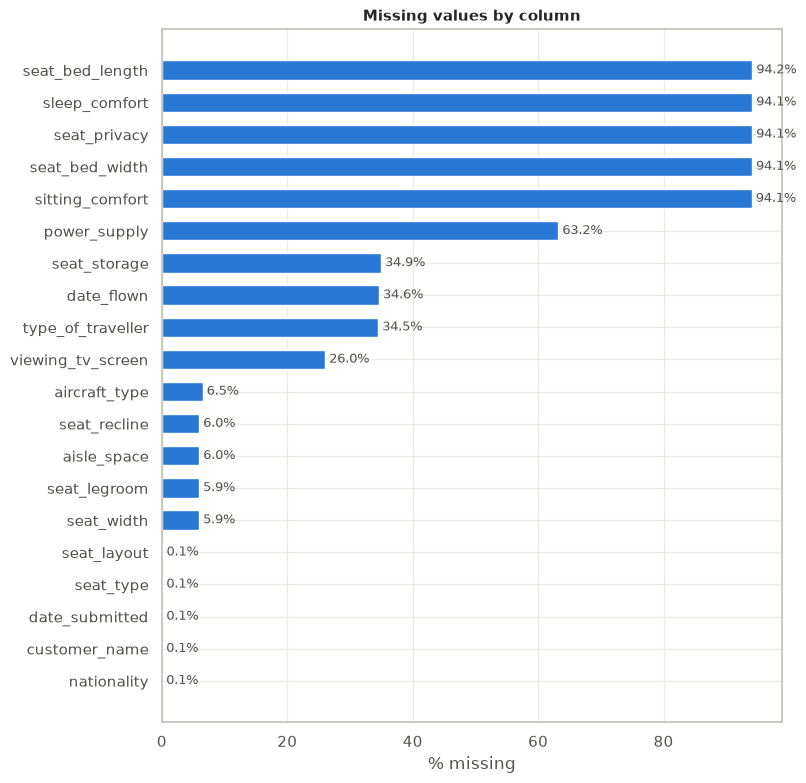

In [20]:
if len(missing):
    fig, ax = plt.subplots(figsize=(8, 0.4 * len(missing) + 1))
    ax.barh(missing.index, missing["pct_missing"], color=MAIN, height=0.6)
    ax.invert_yaxis()
    ax.set_xlabel("% missing")
    ax.set_title("Missing values by column")
    for i, v in enumerate(missing["pct_missing"]):
        ax.text(v, i, f" {v:.1f}%", va="center", color="#52514e", fontsize=9)
    save_fig(fig, "missing_values")
    plt.show()

In [21]:
# Do nulls co-occur? (same rows missing several fields -> one upstream cause)
if len(missing) > 1:
    display(df[missing.index].isna().corr().round(2))

,seat_bed_length,sleep_comfort,seat_privacy,seat_bed_width,sitting_comfort,power_supply,seat_storage,date_flown,type_of_traveller,viewing_tv_screen,aircraft_type,seat_recline,aisle_space,seat_legroom,seat_width,seat_layout,seat_type,date_submitted,customer_name,nationality
seat_bed_length,1.00,0.99,1.00,1.00,0.99,0.24,0.17,0.18,0.18,-0.41,0.06,-0.98,-0.98,-0.98,-0.98,0.01,0.01,0.01,0.01,0.01
sleep_comfort,0.99,1.00,0.99,0.99,1.00,0.25,0.17,0.18,0.18,-0.42,0.06,-0.98,-0.98,-0.99,-0.99,0.01,0.01,0.01,0.01,0.01
seat_privacy,1.00,0.99,1.00,0.99,1.00,0.24,0.17,0.18,0.18,-0.42,0.06,-0.98,-0.98,-0.99,-0.99,0.01,0.01,0.01,0.01,0.01
seat_bed_width,1.00,0.99,0.99,1.00,1.00,0.25,0.17,0.18,0.18,-0.42,0.06,-0.99,-0.99,-0.99,-0.99,0.01,0.01,0.01,0.01,0.01
sitting_comfort,0.99,1.00,1.00,1.00,1.00,0.25,0.17,0.18,0.18,-0.42,0.06,-0.99,-0.99,-0.99,-0.99,0.01,0.01,0.01,0.01,0.01
power_supply,0.24,0.25,0.24,0.25,0.25,1.00,0.56,0.56,0.55,0.11,0.16,-0.24,-0.24,-0.24,-0.24,0.02,0.02,0.02,0.02,0.02
seat_storage,0.17,0.17,0.17,0.17,0.17,0.56,1.00,0.99,0.99,-0.37,0.21,-0.17,-0.17,-0.17,-0.17,-0.02,0.04,0.04,0.03,0.03
date_flown,0.18,0.18,0.18,0.18,0.18,0.56,0.99,1.00,1.00,-0.38,0.21,-0.18,-0.18,-0.18,-0.18,-0.02,0.04,0.04,0.03,0.03
type_of_traveller,0.18,0.18,0.18,0.18,0.18,0.55,0.99,1.00,1.00,-0.38,0.21,-0.18,-0.18,-0.18,-0.18,-0.02,0.04,0.04,0.03,0.03
viewing_tv_screen,-0.41,-0.42,-0.42,-0.42,-0.42,0.11,-0.37,-0.38,-0.38,1.00,-0.00,0.42,0.42,0.42,0.42,0.02,-0.02,-0.02,-0.01,-0.01


In [22]:
# Rows with a missing TARGET cannot be used for supervised training
if TARGET and df[TARGET].isna().any():
    print(f"{df[TARGET].isna().sum()} rows have no {TARGET} -> drop before modelling")

## 4.2 Outliers<a id="sec-4-2"></a>

**Detect, don't delete.** Flag values outside `Q1 - 1.5·IQR` / `Q3 + 1.5·IQR`, then decide per column:
real but rare (keep, maybe log-transform) vs. error (fix in 3.5).

In [23]:
num_cols = [c for c in df.select_dtypes("number").columns
            if c not in ID_COLS and df[c].nunique() > 2]
if num_cols:
    outliers = outlier_report(df, num_cols)
    display(outliers[outliers.n_outliers > 0])
else:
    print("No numeric columns besides the id: nothing to check.")

,lower,upper,min,max,n_outliers,pct_outliers
column,,,,,,


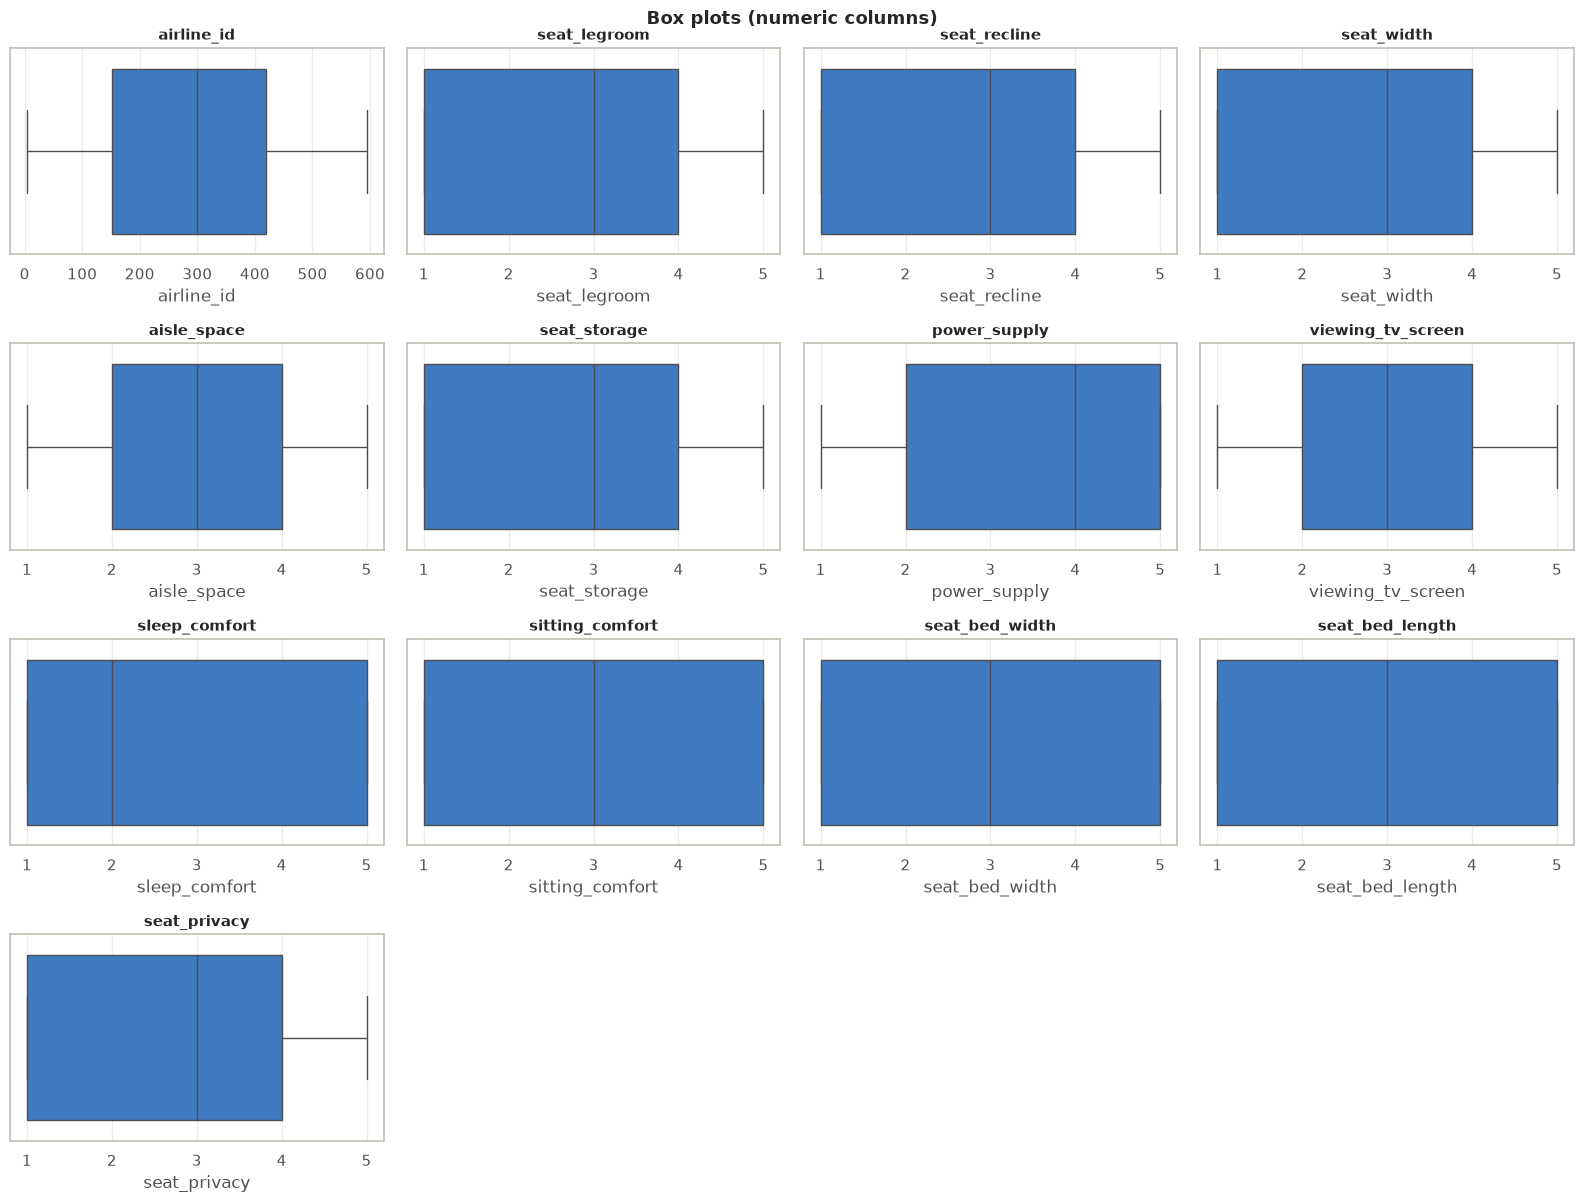

In [24]:
plot_grid(num_cols, lambda c, ax: sns.boxplot(x=df[c], ax=ax, color=MAIN, fliersize=3, linewidth=1),
          title="Box plots (numeric columns)", name="boxplots")

# 5. Attribute Combination<a id="sec-5"></a>

Create features that may explain the data better than the raw columns (ratios, rates, flags, date parts).
They go through the same EDA as everything else below.

how long after the trip the review was written, review length, how many ratings were filled in, review year.

In [25]:
# How long after the trip was the review written, how long is it, and how many ratings were filled in?
visit_col = next((c for c in ["date_flown", "date_visit"] if c in df.columns), None)
rating_cols = df.select_dtypes("float").columns.tolist()
if visit_col:
    df["days_to_review"] = (df["date_submitted"] - df[visit_col]).dt.days
df["review_length"] = df["review"].str.len()
df["n_ratings_filled"] = df[rating_cols].notna().sum(axis=1)
df["submitted_year"] = df["date_submitted"].dt.year


# 6. EDA<a id="sec-6"></a>

## 6.0 Classify Attributes<a id="sec-6-0"></a>

Every plot below is driven by these groups. Override with `CAT_COLS` in the config if a group looks wrong.

In [26]:
groups = classify_columns(df, TARGET, ID_COLS, CAT_COLS, CAT_MAX_UNIQUE)
for name, cols in groups.items():
    print(f"{name:<12} ({len(cols):>2}): {cols}")

const_attribs = groups["constant"]
bin_attribs = groups["binary"]
cat_attribs = groups["categorical"]
disc_attribs = groups["discrete"]
cont_attribs = groups["continuous"]
num_attribs = disc_attribs + cont_attribs

constant     ( 1): ['updated_at']
binary       ( 1): ['verify']
categorical  (10): ['airline_id', 'type_of_traveller', 'seat_type', 'aircraft_type', 'seat_layout', 'date_submitted', 'date_flown', 'customer_name', 'nationality', 'review']
discrete     (13): ['seat_legroom', 'seat_recline', 'seat_width', 'aisle_space', 'seat_storage', 'power_supply', 'viewing_tv_screen', 'sleep_comfort', 'sitting_comfort', 'seat_bed_width', 'seat_bed_length', 'seat_privacy', 'n_ratings_filled']
continuous   ( 3): ['days_to_review', 'review_length', 'submitted_year']


In [27]:
# Constant columns carry no information
if const_attribs:
    print("Dropping constant columns:", const_attribs)
    df = df.drop(columns=const_attribs)

# High-cardinality text columns (e.g. free text, raw model names) swamp plots
high_card = [c for c in cat_attribs if df[c].nunique() > 50]
print("High-cardinality categoricals (summarised, not plotted):", high_card)
cat_plot_attribs = [c for c in cat_attribs if c not in high_card]

Dropping constant columns: ['updated_at']
High-cardinality categoricals (summarised, not plotted): ['airline_id', 'aircraft_type', 'seat_layout', 'date_submitted', 'date_flown', 'customer_name', 'nationality', 'review']


## 6.1 Univariate<a id="sec-6-1"></a>

One column at a time: shape, spread, skew, rare levels.

### 6.1.1 Target

The target is `recommended`: the share of reviews that recommend (class balance). A rate far from 50% is normal here; it is the baseline every segment is compared with.

,count,pct
recommended,,
False,2122,56.39
True,1641,43.61


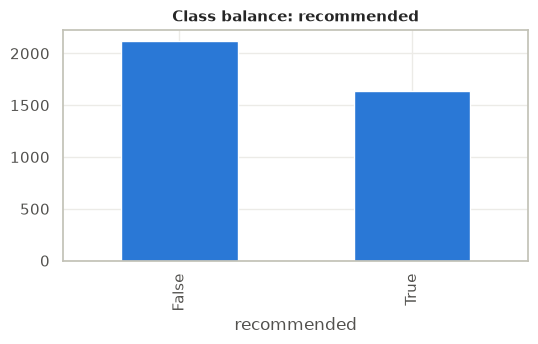

In [28]:
if TARGET and PROBLEM_TYPE == "regression":
    y = df[TARGET].dropna()
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    sns.histplot(y, kde=True, ax=axes[0], color=MAIN)
    axes[0].set_title(f"{TARGET} (skew = {y.skew():.2f})")
    sns.histplot(np.log1p(y), kde=True, ax=axes[1], color=MAIN)
    axes[1].set_title(f"log1p({TARGET}) (skew = {np.log1p(y).skew():.2f})")
    fig.tight_layout()
    save_fig(fig, "target_distribution")
    plt.show()
    display(y.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame())
elif TARGET:
    counts = df[TARGET].value_counts()
    display(pd.DataFrame({"count": counts, "pct": counts / counts.sum() * 100}))
    fig, ax = plt.subplots(figsize=(6, 3))
    counts.plot.bar(ax=ax, color=MAIN)
    ax.set_title(f"Class balance: {TARGET}")
    save_fig(fig, "target_distribution")
    plt.show()

### 6.1.2 Numeric

In [29]:
skew = df[num_attribs].skew().sort_values(key=abs, ascending=False).to_frame("skew")
skew["shape"] = pd.cut(skew["skew"].abs(), [-np.inf, 0.5, 1, np.inf], labels=["symmetric", "moderate", "highly skewed"])
skew

,skew,shape
days_to_review,3.17,highly skewed
review_length,2.21,highly skewed
power_supply,-0.58,moderate
sleep_comfort,0.32,symmetric
n_ratings_filled,0.31,symmetric
submitted_year,0.21,symmetric
seat_recline,0.20,symmetric
seat_bed_length,-0.18,symmetric
viewing_tv_screen,-0.17,symmetric
seat_privacy,0.16,symmetric


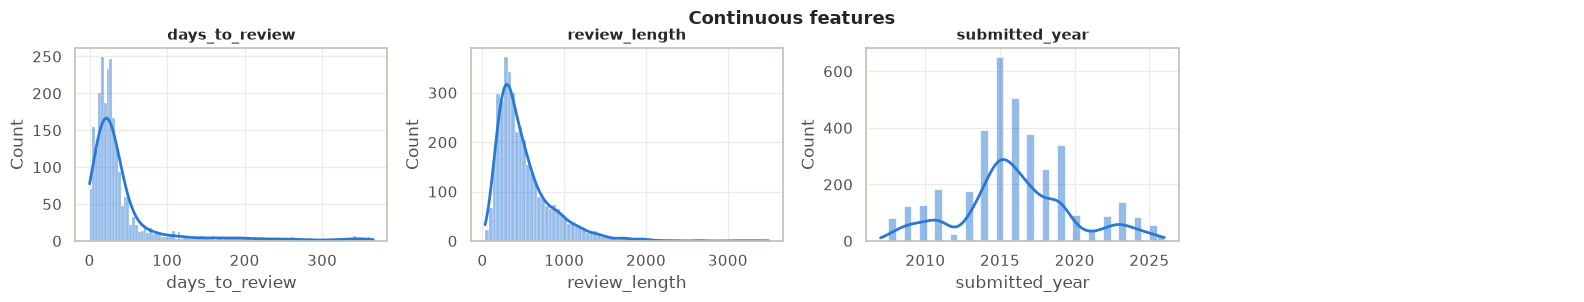

In [30]:
plot_grid(cont_attribs, lambda c, ax: sns.histplot(df[c], kde=True, ax=ax, color=MAIN),
          title="Continuous features", name="hist_continuous")

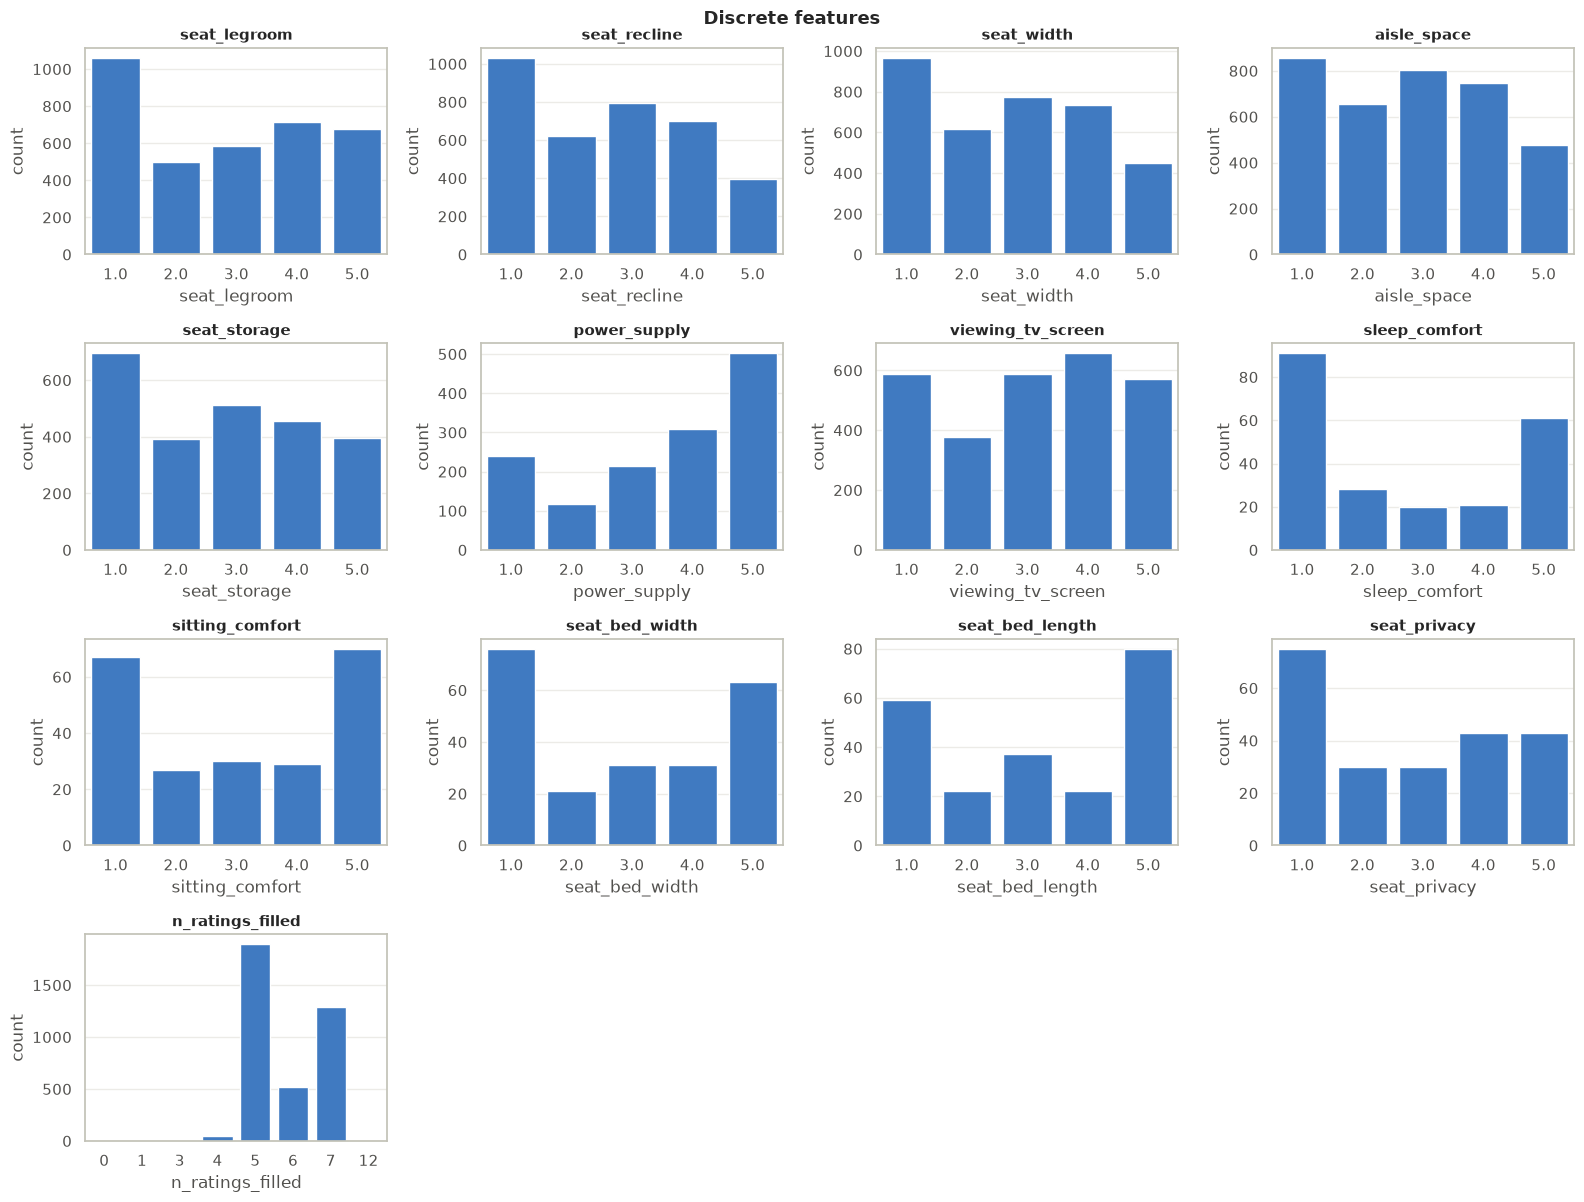

In [31]:
plot_grid(disc_attribs, lambda c, ax: sns.countplot(x=df[c], ax=ax, color=MAIN),
          title="Discrete features", name="count_discrete")

### 6.1.3 Binary

In [32]:
if bin_attribs:
    binary_share = (df[bin_attribs]
                    .apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100)
                    .sort_values(ascending=False)
                    .to_frame("pct_majority_value"))
    binary_share["near_constant"] = binary_share["pct_majority_value"] > 95
    display(binary_share)
else:
    print("No binary columns.")

,pct_majority_value,near_constant
verify,75.50,False


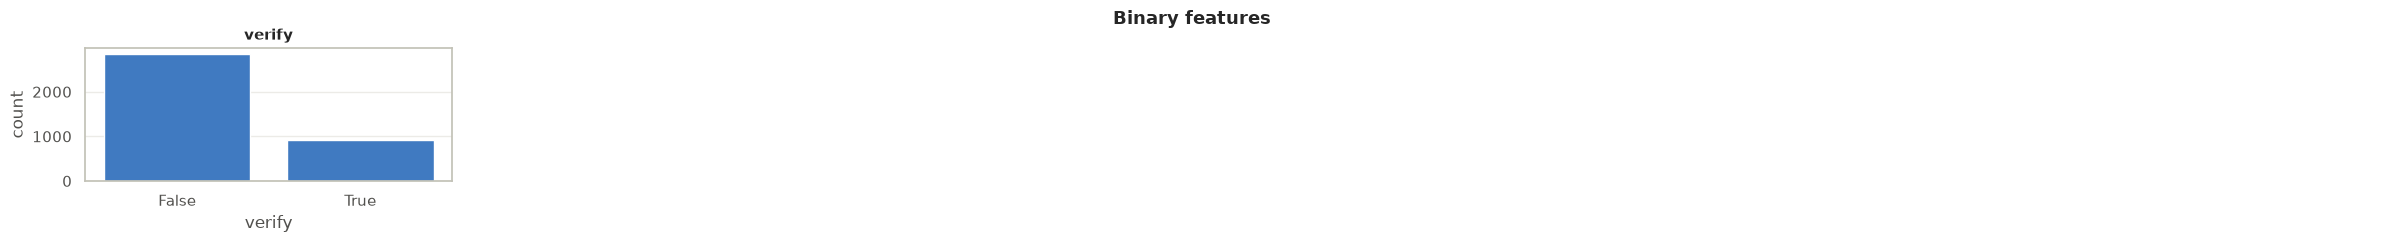

In [33]:
plot_grid(bin_attribs, lambda c, ax: sns.countplot(x=df[c], ax=ax, color=MAIN),
          ncols=6, height=2.4, title="Binary features", name="count_binary")

### 6.1.4 Categorical

In [34]:
for col in high_card:
    print(f"{col}: {df[col].nunique()} levels; top 5:")
    display(df[col].value_counts().head(5).to_frame())

airline_id: 205 levels; top 5:


,count
airline_id,
419,333
151,203
168,144
212,143
331,130


aircraft_type: 63 levels; top 5:


,count
aircraft_type,
Airbus A330,387
Airbus A320,340
Airbus A380,324
Boeing 777,270
Boeing 747-400,229


seat_layout: 78 levels; top 5:


,count
seat_layout,
3x3,895
2x4x2,835
3x4x3,749
3x3x3,560
2x3x2,214


... (6 outputs left out)

nationality: 97 levels; top 5:


,count
nationality,
United Kingdom,945
United States,736
Australia,412
Canada,235
Germany,130


review: 3430 levels; top 5:


,count
review,
"This is the worst economy seating I have been on, the seats are very narrow and the seating hard. Having the back upright feels like you are being pushed froward, in recline they are just about tolerable. The leg room is very tight that cannot move your feet. There is no arm room and if you are in an aisle seat you are constantly being knocked by passengers and crew as they pass. The earphone socket was broken i had an 8hr flight with no entertainment.",2
"BA used a configuration of 2x3x2 seats per row. I was seated in a middle, small, claustrophobic cabin in the middle with no air flow. Service was handled over a passenger seating on both sides and stepping to the aisle required jumping over another passenger.",2
"The business class of British Airways flying London to LA is very poor by comparison to other airlines, for the price. The seating is narrow, on top of a neighbor, no separate little cabin. It's also generally more expensive and the Avios are not worth collecting as there is rarely any availability.",2
"Was sat on that famous row 35, seat 35H. Summary: 11.5 hours flight from LHR to GIG in seat that doesn't recline by default. The seats on the row 34 ahead recline, meaning it's a struggle for eating or drinking if passengers sat on row 34 keep their seats reclined. To make the disaster worse, the overhead bin compartment above rows 33 to 35 are occupied by cabin crew stuff. Means that it is extremely difficult to accommodate cabin luggage.",2
"Recently flew BA’s nonstop between Boston and London on the A380. It is a massive airplane with a payload of over 500 passengers. Business class seating on this plane and on this route was not worth the $$ in my opinion. There were too many seats in each row making the seats narrower than those offered by other airlines. Most jumbo jets have a 1-2-1 configuration in business class; this plane had 2-3-2 and 2-4-2, twice as many seats in each row. This is particularly obnoxious if you are seated in the middle aisle because that means anyone seated in a window seat or in the middle seats has to crawl over an aisle passenger just to get to the bathroom and back. If you do so in the dark on an overnight flight, it is actually unsafe for you and that poor aisle passenger. Check the plane scheduled for the flight you want to take and if a 777 is offered, opt for that one. They are all equipped with Club Suites in Business now.",2


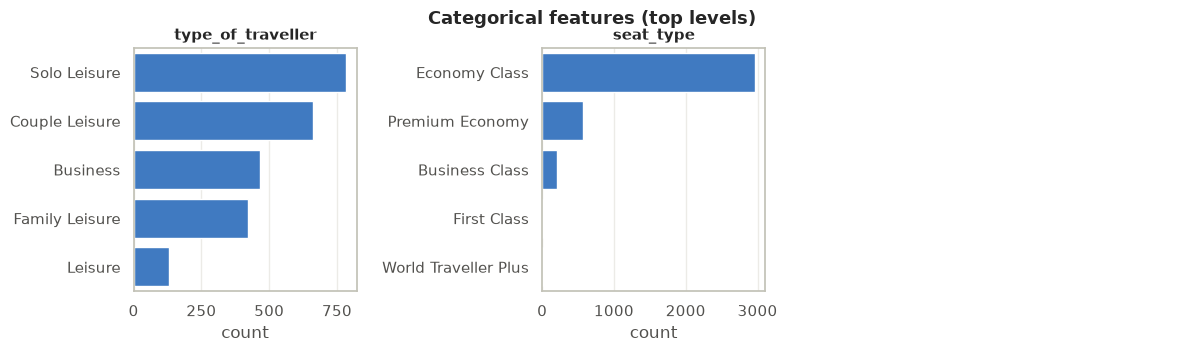

In [35]:
def plot_top_categories(col, ax):
    counts = df[col].value_counts()
    top = counts.head(TOP_N_CATEGORIES)
    sns.barplot(x=top.values, y=top.index.astype(str), ax=ax, color=MAIN, orient="h")
    ax.set_xlabel("count")
    ax.set_ylabel("")

plot_grid(cat_plot_attribs, plot_top_categories, ncols=3, height=3.5,
          title="Categorical features (top levels)", name="count_categorical")

In [36]:
# Rare levels (< 1% of rows) - candidates for grouping into "other"
rare = {c: df[c].value_counts(normalize=True).loc[lambda s: s < 0.01].index.tolist() for c in cat_plot_attribs}
{c: v for c, v in rare.items() if v}

{'seat_type': ['First Class', 'World Traveller Plus']}

## 6.2 Bivariate<a id="sec-6-2"></a>

Each feature against **`recommended`**. This is where the candidate drivers come from. The charts show, for each rating value, the share of reviews that recommend; the last cell ranks the ratings by how strongly they move with `recommended`.

In [37]:
if TARGET and PROBLEM_TYPE == "regression":
    target_corr = (df[num_attribs + bin_attribs + [TARGET]]
                   .corr(method="spearman")[TARGET]
                   .drop(TARGET)
                   .sort_values(key=abs, ascending=False))
    fig, ax = plt.subplots(figsize=(7, 0.28 * len(target_corr) + 1))
    colors = np.where(target_corr > 0, PALETTE[7], PALETTE[0])
    ax.barh(target_corr.index, target_corr.values, color=colors, height=0.7)
    ax.axvline(0, color="#52514e", linewidth=1)
    ax.invert_yaxis()
    ax.set_xlabel(f"Spearman correlation with {TARGET}")
    ax.set_title(f"Features ranked by correlation with {TARGET}")
    save_fig(fig, "target_correlation")
    plt.show()

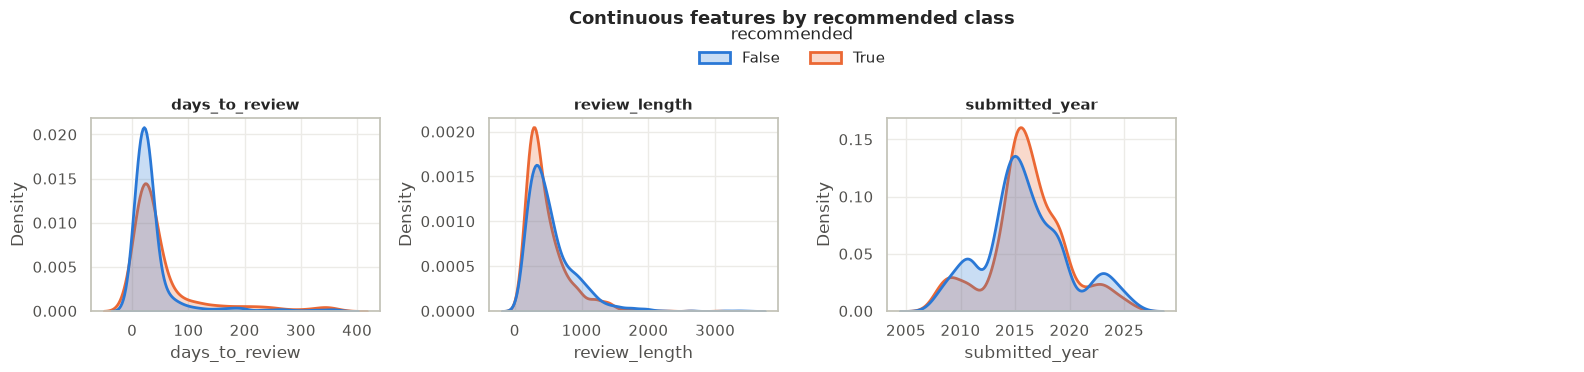

In [38]:
if TARGET and PROBLEM_TYPE == "regression":
    top_num = [c for c in target_corr.index if c in cont_attribs][:8]
    plot_grid(top_num,
              lambda c, ax: sns.regplot(data=df, x=c, y=TARGET, ax=ax, lowess=True,
                                        scatter_kws={"s": 8, "alpha": 0.35, "color": MAIN},
                                        line_kws={"color": PALETTE[1]}),
              title=f"Top continuous features vs {TARGET} (LOWESS trend)", name="scatter_vs_target")
elif TARGET:
    plot_grid(cont_attribs,
              lambda c, ax: sns.kdeplot(data=df, x=c, hue=TARGET, common_norm=False, fill=True,
                                        alpha=0.25, linewidth=2, ax=ax),
              title=f"Continuous features by {TARGET} class", name="dist_by_target", shared_legend=True)

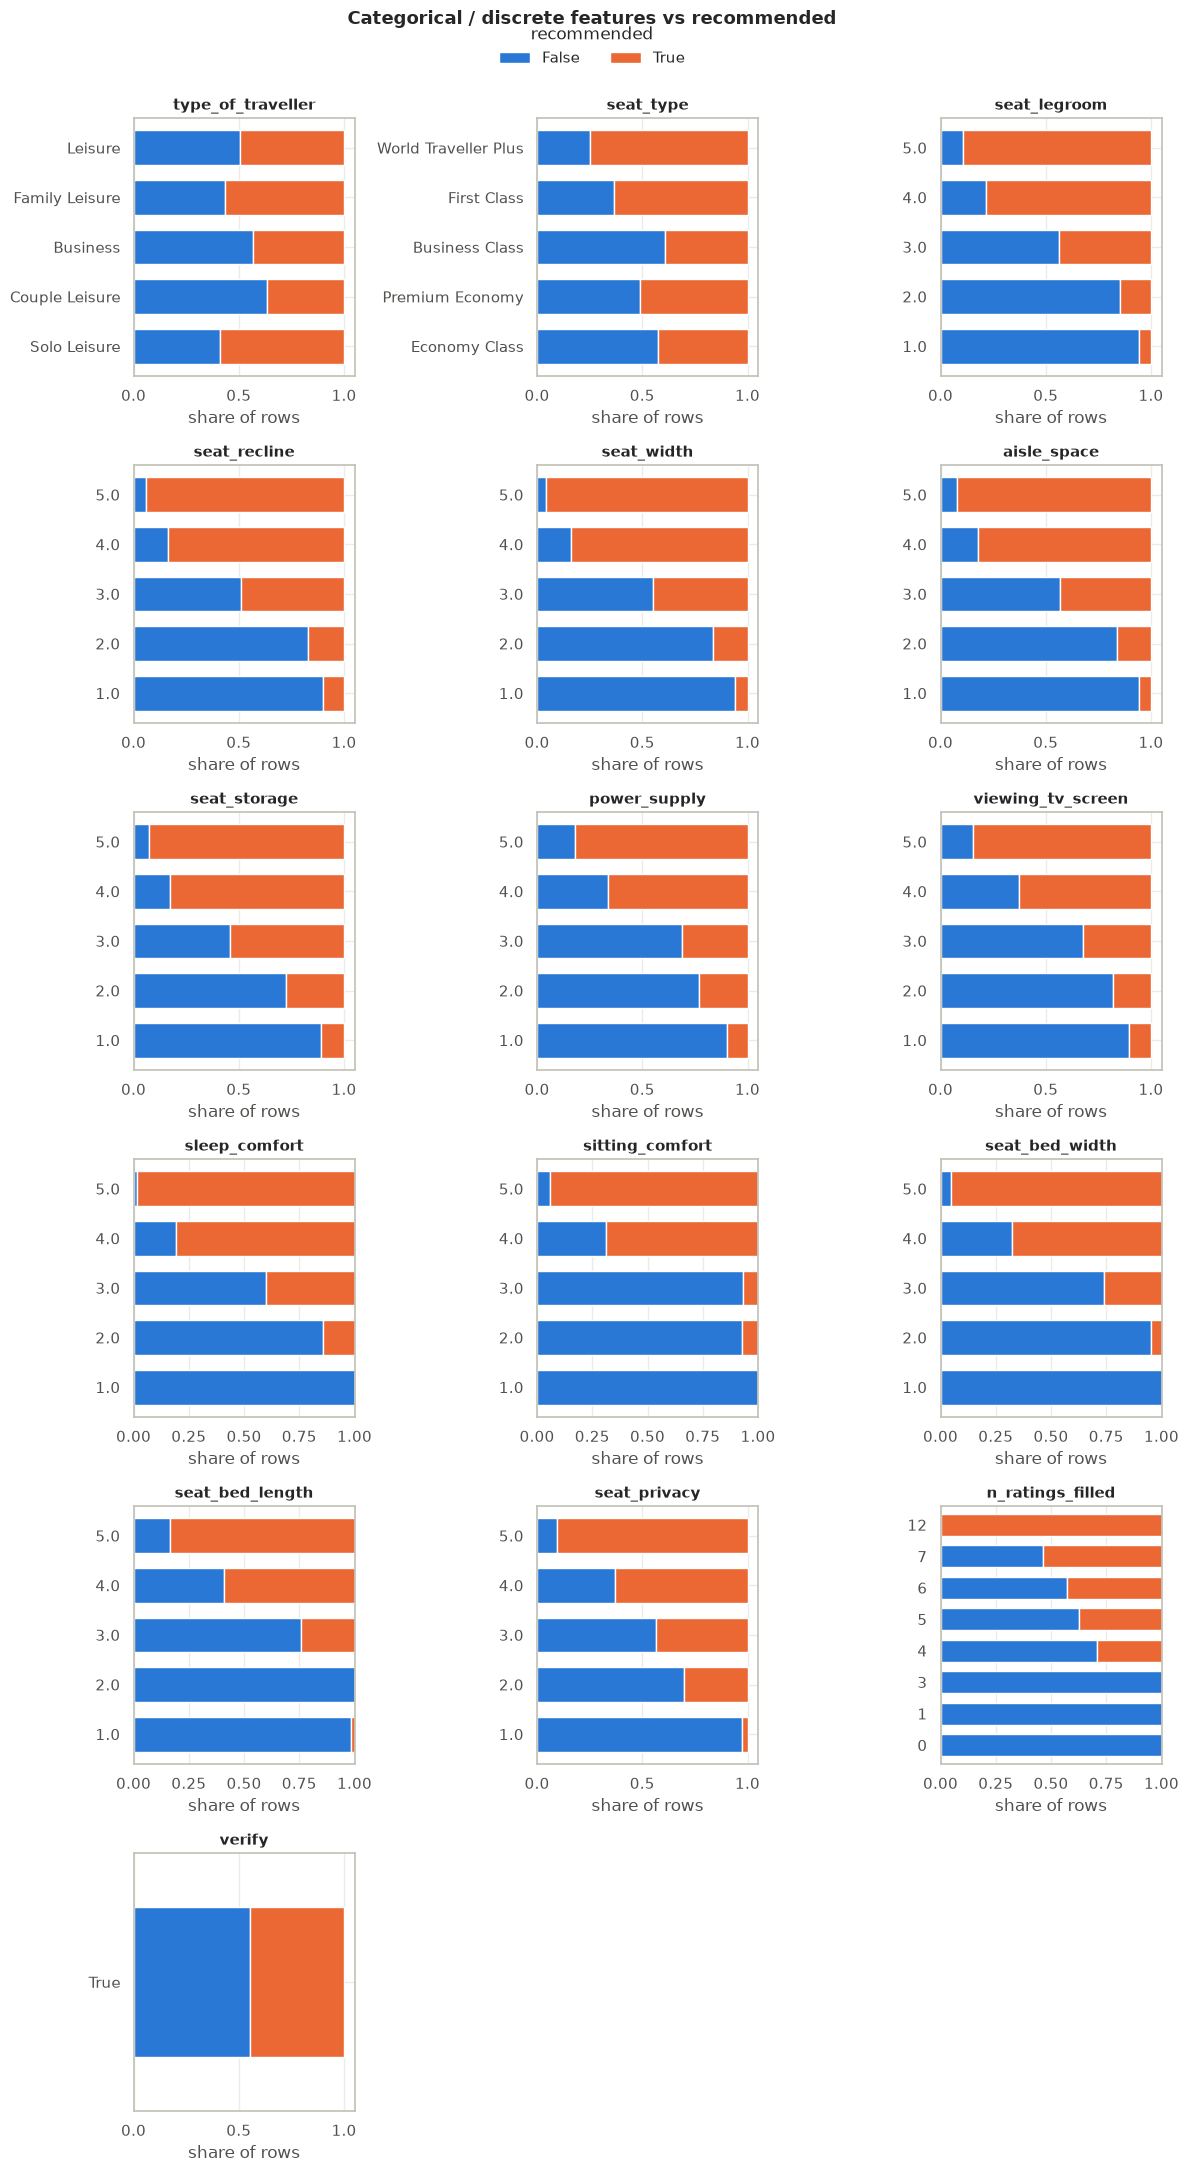

In [39]:
def plot_cat_vs_target(col, ax):
    order = df[col].value_counts().head(TOP_N_CATEGORIES).index
    if pd.api.types.is_numeric_dtype(df[col]):
        order = order.sort_values()
    if PROBLEM_TYPE == "regression":
        sns.boxplot(data=df[df[col].isin(order)], x=TARGET, y=col, order=order,
                    ax=ax, color=MAIN, fliersize=2, linewidth=1, orient="h")
    else:
        rate = pd.crosstab(df[col], df[TARGET], normalize="index").loc[order]
        rate.plot.barh(stacked=True, ax=ax, width=0.7, edgecolor="white", linewidth=1)
        ax.set_xlabel("share of rows")
    ax.set_ylabel("")

if TARGET:
    by_level = cat_plot_attribs + disc_attribs + (bin_attribs if PROBLEM_TYPE == "classification" else [])
    plot_grid(by_level, plot_cat_vs_target, ncols=3, height=3.5,
              title=f"Categorical / discrete features vs {TARGET}", name="cat_vs_target", shared_legend=True)

In [40]:
# Binary flags: difference in median target between the two groups (a = lower value, b = higher)
if TARGET and PROBLEM_TYPE == "regression":
    rows = {}
    for col in bin_attribs:
        a, b = sorted(df[col].dropna().unique())
        y_a, y_b = df.loc[df[col] == a, TARGET].dropna(), df.loc[df[col] == b, TARGET].dropna()
        rows[col] = {"a": a, "b": b, "median_when_a": y_a.median(), "median_when_b": y_b.median(),
                     "share_of_b": (df[col] == b).mean(), "p_value": stats.mannwhitneyu(y_a, y_b).pvalue}
    lift = pd.DataFrame(rows).T
    lift["diff"] = (lift["median_when_b"] - lift["median_when_a"]).astype(float)
    display(lift.sort_values("diff", key=abs, ascending=False))

In [41]:
# Which rating moves most with `recommended`? Spearman correlation of each rating with recommended (0/1).
# "Goes with", not "causes": this is observed data.
rating_cols = [c for c in df.select_dtypes("float").columns if c in MEANINGS]
recommended_01 = df[TARGET].astype("float")
driver_rank = (df[rating_cols].apply(lambda s: s.corr(recommended_01, method="spearman"))
               .sort_values(ascending=False).to_frame("spearman_with_recommended"))
driver_rank["n_rated"] = df[rating_cols].notna().sum()
display(driver_rank.round(2))

# Same ranking inside each of the 3 biggest segments (seat_type): does the order change?
segment_col = "seat_type"
top_segments = df[segment_col].value_counts().head(3).index
by_segment = pd.DataFrame({
    seg: df.loc[df[segment_col] == seg, rating_cols].apply(
        lambda s: s.corr(df.loc[df[segment_col] == seg, TARGET].astype("float"), method="spearman"))
    for seg in top_segments})
display(by_segment.round(2))


,spearman_with_recommended,n_rated
sleep_comfort,0.85,221
sitting_comfort,0.81,223
seat_bed_width,0.81,222
seat_bed_length,0.72,220
seat_width,0.68,3540
seat_legroom,0.68,3540
seat_privacy,0.67,221
aisle_space,0.66,3539
seat_recline,0.64,3539
seat_storage,0.63,2448


/home/trung/dbt_projects/dbt_duckdb_skytrax/.venv/lib/python3.12/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
/home/trung/dbt_projects/dbt_duckdb_skytrax/.venv/lib/python3.12/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
/home/trung/dbt_projects/dbt_duckdb_skytrax/.venv/lib/python3.12/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
/home/trung/dbt_projects/dbt_duckdb_skytrax/.venv/lib/python3.12/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
/home/trung/dbt_projects/dbt_duckdb_skytrax/.venv/lib/python3.12/site-packages/panda

,Economy Class,Premium Economy,Business Class
seat_legroom,0.69,0.65,NaN
seat_recline,0.63,0.66,NaN
seat_width,0.68,0.67,NaN
aisle_space,0.67,0.62,NaN
seat_storage,0.62,0.66,0.67
power_supply,0.53,0.58,0.71
viewing_tv_screen,0.54,0.63,NaN
sleep_comfort,NaN,NaN,0.85
sitting_comfort,NaN,NaN,0.81
seat_bed_width,NaN,NaN,0.81


## 6.3 Multivariate<a id="sec-6-3"></a>

Features against **each other**: redundancy, leakage, interactions.

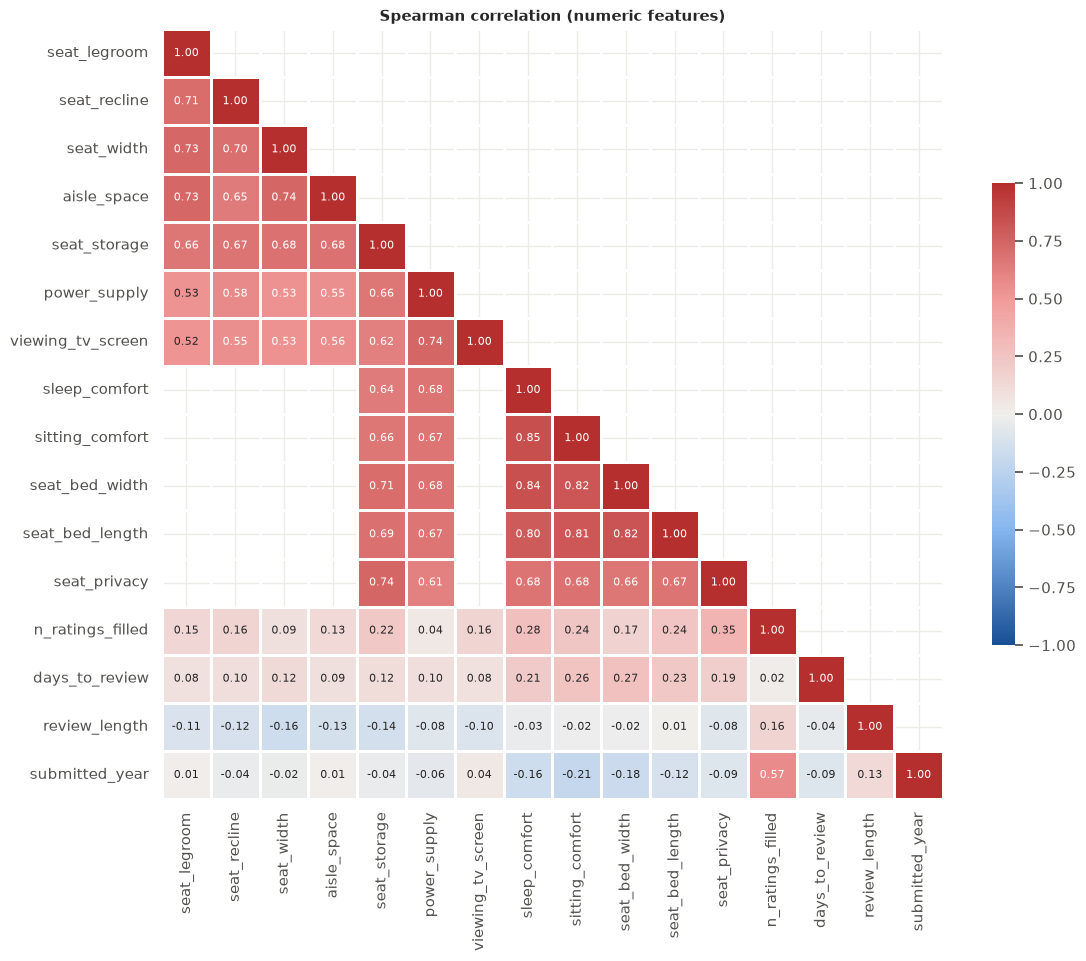

In [42]:
corr_cols = num_attribs
if len(corr_cols) >= 2:
    corr = df[corr_cols].corr(method="spearman")
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

    fig, ax = plt.subplots(figsize=(0.6 * len(corr) + 3, 0.5 * len(corr) + 2))
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap=DIVERGING, vmin=-1, vmax=1, center=0,
                linewidths=2, linecolor="white", annot_kws={"size": 8}, cbar_kws={"shrink": 0.6}, ax=ax)
    ax.set_title("Spearman correlation (numeric features)")
    save_fig(fig, "correlation_heatmap")
    plt.show()
else:
    print("Fewer than two numeric columns: no correlation to show.")

In [43]:
# Highly correlated pairs -> keep one of each pair (or combine) before modelling
if len(corr_cols) >= 2:
    pairs = (corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1))
             .stack()
             .rename("r")
             .reset_index()
             .rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
    display(pairs[pairs.r.abs() >= HIGH_CORR].sort_values("r", key=abs, ascending=False))

,feature_a,feature_b,r
120,sleep_comfort,sitting_comfort,0.85
121,sleep_comfort,seat_bed_width,0.84
154,seat_bed_width,seat_bed_length,0.82
137,sitting_comfort,seat_bed_width,0.82
138,sitting_comfort,seat_bed_length,0.81


In [44]:
# Leakage check: ID columns or row order should NOT predict the target
if TARGET and PROBLEM_TYPE == "regression":
    for col in ID_COLS:
        if col in df.columns:
            r = df[[col, TARGET]].corr(method="spearman").iloc[0, 1]
            print(f"corr({col}, {TARGET}) = {r:.2f}" + ("  <-- rows are ordered; shuffle before splitting" if abs(r) > 0.3 else ""))

### 6.3.1 Segments

Three views that answer the business questions: (1) the mean rating and recommend rate of each segment (`HUE`), (2) the trend by review year, (3) how many airlines or airports have enough reviews to be compared.
Hue splits use at most 3 groups; smaller groups fold into "other".

,n_reviews,recommend_rate
seat_type,,
Economy Class,2962,0.42
Premium Economy,567,0.51
Business Class,212,0.39
other,19,0.68


seat_type,Business Class,Economy Class,Premium Economy,other
seat_legroom,4.00,2.71,3.51,4.00
seat_recline,4.00,2.60,2.93,3.75
seat_width,4.00,2.66,3.14,4.00
aisle_space,4.00,2.75,3.13,4.00
seat_storage,2.96,2.72,2.95,3.55
power_supply,3.57,3.44,3.73,4.67
viewing_tv_screen,4.00,3.06,3.19,4.25
sleep_comfort,2.65,NaN,NaN,3.60
sitting_comfort,3.00,NaN,NaN,3.73
seat_bed_width,2.87,NaN,NaN,4.00


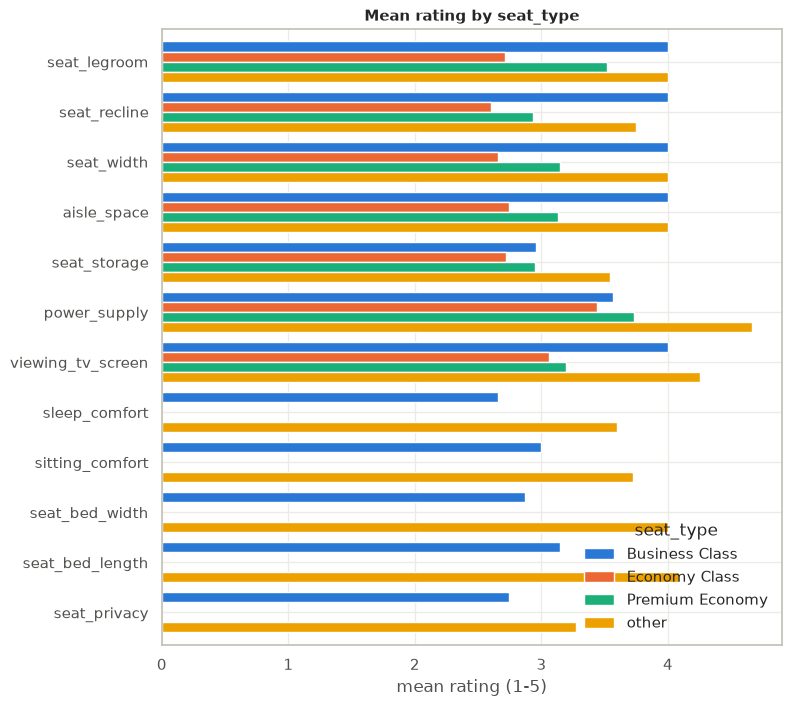

In [45]:
HUE = "seat_type"   # the column that splits the rows into segments

if HUE in df.columns:
    # Keep the 3 biggest groups, fold the rest into "other"
    segmented = df[df[HUE].notna()]
    keep = segmented[HUE].value_counts().head(3).index
    segmented = segmented.assign(**{HUE: segmented[HUE].where(segmented[HUE].isin(keep), "other")})

    rating_cols = [c for c in df.select_dtypes("float").columns if c in MEANINGS]
    mean_rating = segmented.groupby(HUE)[rating_cols].mean().T      # rows = ratings, columns = segments
    segment_size = segmented[HUE].value_counts().to_frame("n_reviews")
    segment_size["recommend_rate"] = segmented[TARGET].astype("float").groupby(segmented[HUE]).mean()
    display(segment_size.round(2))
    display(mean_rating.round(2))

    fig, ax = plt.subplots(figsize=(8, 0.5 * len(rating_cols) + 2))
    mean_rating.plot.barh(ax=ax, width=0.8)
    ax.invert_yaxis()
    ax.set_xlabel("mean rating (1-5)")
    ax.set_title(f"Mean rating by {HUE}")
    ax.legend(title=HUE, frameon=False)
    plt.show()


,n_reviews,recommend_rate,seat_legroom,seat_recline,seat_width,aisle_space,seat_storage,power_supply,viewing_tv_screen,sleep_comfort,sitting_comfort,seat_bed_width,seat_bed_length,seat_privacy
submitted_year,,,,,,,,,,,,,,
"2,007.00",5,0.60,3.20,3.40,3.20,3.20,NaN,NaN,3.40,NaN,NaN,NaN,NaN,NaN
"2,008.00",81,0.49,2.99,2.90,2.86,2.86,NaN,NaN,2.83,NaN,NaN,NaN,NaN,NaN
"2,009.00",124,0.48,2.95,3.01,2.98,3.02,NaN,NaN,3.19,NaN,NaN,NaN,NaN,NaN
"2,010.00",126,0.31,2.79,2.49,2.90,2.95,NaN,NaN,3.26,NaN,NaN,NaN,NaN,NaN
"2,011.00",182,0.26,2.54,2.47,2.59,2.78,NaN,NaN,2.99,NaN,NaN,NaN,NaN,NaN
"2,012.00",24,0.21,2.62,2.33,2.50,2.29,NaN,NaN,2.73,NaN,NaN,NaN,NaN,NaN
"2,013.00",178,0.37,2.85,2.86,2.83,2.64,NaN,NaN,3.13,NaN,NaN,NaN,NaN,NaN
"2,014.00",391,0.32,2.70,2.53,2.52,2.61,NaN,NaN,2.83,NaN,NaN,NaN,NaN,NaN
"2,015.00",650,0.48,2.88,2.70,2.80,2.79,2.85,3.60,3.10,NaN,NaN,NaN,NaN,NaN


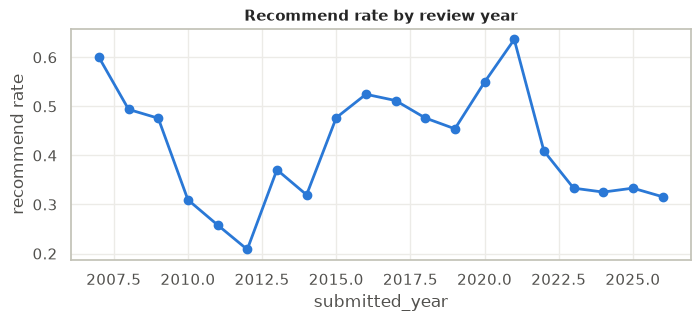

In [46]:
# Trend by review year: number of reviews, recommend rate and mean rating of each aspect
rating_cols = [c for c in df.select_dtypes("float").columns if c in MEANINGS]
yearly = df.groupby("submitted_year").agg(n_reviews=("review_id", "size"))
yearly["recommend_rate"] = df[TARGET].astype("float").groupby(df["submitted_year"]).mean()
display(yearly.round(2).join(df.groupby("submitted_year")[rating_cols].mean().round(2)))

fig, ax = plt.subplots(figsize=(8, 3))
yearly["recommend_rate"].plot(ax=ax, marker="o", color=MAIN)
ax.set_ylabel("recommend rate")
ax.set_title("Recommend rate by review year")
plt.show()


In [47]:
# Peer rule: only compare a airline that has at least 100 reviews
reviews_per_airline = df["airline_id"].value_counts()
enough = reviews_per_airline >= 100
print(f"{enough.sum()} of {len(enough)} airlines have at least 100 reviews")
print(f"They hold {reviews_per_airline[enough].sum() / len(df):.0%} of all reviews")


13 of 205 airlines have at least 100 reviews
They hold 49% of all reviews


In [48]:
# Pairplot of the strongest features (slow on wide data - keep it small)
if TARGET and PROBLEM_TYPE == "regression":
    pp_cols = [c for c in target_corr.index if c in cont_attribs][:4] + [TARGET]
    g = sns.pairplot(df[pp_cols].dropna(), corner=True, plot_kws={"s": 8, "alpha": 0.35, "color": MAIN},
                     diag_kws={"color": MAIN})
    g.figure.suptitle("Pairplot: strongest continuous features", y=1.02)
    save_fig(g.figure, "pairplot")
    plt.show()

# 7. Summary of Findings<a id="sec-7"></a>

The deliverable: one answer per question from 1.2, then the actions before staging. Drafted from the data, to be reviewed.
*Numbers come from running this notebook on the CSV. Counts printed from 3.5 onward are taken after the duplicates dropped in 3.4, so they can be slightly lower than counts on the raw file.*

**Answers to the questions in 1.2**
| # | Answer |
|---|---|
| D1 | Usable after cleaning: `seat_layout` and the 1970 dates are the main problems. |
| Q1 | In economy the lowest mean rating is `seat_recline` (2.60), then `seat_width` (2.66), `seat_legroom` (2.71), `seat_storage` (2.72) and `aisle_space` (2.75): all seat aspects are weak, none stands out. |
| Q2 | `seat_width` and `seat_legroom` go with `recommended` the most among the core aspects (Spearman 0.68), then `aisle_space` 0.66, `seat_recline` 0.64, `seat_storage` 0.63; `power_supply` and `viewing_tv_screen` are lowest (0.56). In economy the order is the same (legroom 0.69, width 0.68). |
| Q3 | Only 13 of 205 airlines have at least 100 seat reviews, holding 49% of the reviews: peer comparison by seat is thin. |
| Q4 | The five lie-flat ratings are empty by design (about 94% missing) and four of their pairs are at or above 0.8, so they are redundant with each other. |

**Data quality**
* 3,766 rows x 26 columns; 3 rows are identical except `review_id` (3,763 after 3.4).
* `date_submitted = 1970-01-01` is a placeholder (3 rows left after de-duplication; 6 before).
* `seat_layout` does not look like `NxN(xN)` in 149 of 3,759 values (uppercase `X`, dashes, spaces, texts such as `Aisle`).
* `nationality`: 3 of 3,761 values are not a country (`3x3x3`, `71J`).
* `customer_name` ends with a number in 3,635 rows; 666 rows share their review text with another row.
* Real missing data (do not fill): lie-flat ratings about 94%, `power_supply` 63.2%, `seat_storage` 35.0%, `date_flown` 34.6%, `type_of_traveller` 34.5%, `viewing_tv_screen` 26.0%.

**Target**
* `recommended`: 43.6% of the seat reviews recommend. By cabin: premium economy 51%, economy 42%, business 39% (212 reviews).

**Key drivers**
* Premium ratings go with `recommended` most (`sleep_comfort` 0.85, `sitting_comfort` 0.81, `seat_bed_width` 0.81) but only about 220 reviews rate them. Among the core aspects: `seat_width` 0.68, `seat_legroom` 0.68, `aisle_space` 0.66.

**Redundancy / leakage**
* Pairs at or above 0.8: `sleep_comfort`-`sitting_comfort` 0.85, `sleep_comfort`-`seat_bed_width` 0.84, `seat_bed_width`-`seat_bed_length` 0.82, `sitting_comfort`-`seat_bed_width` 0.82, `sitting_comfort`-`seat_bed_length` 0.81. Keep one or average them.
* `n_ratings_filled` rises with the review year (0.57): the form changed over time.

**Actions before staging**
| Action | Column(s) | Why |
|---|---|---|
| Set to null | `date_submitted` (1970-01-01) | placeholder date |
| Normalise to `NxN(xN)`, null the non-layout texts | `seat_layout` | inconsistent format |
| Keep only values found in the `countries` seed, null the rest | `nationality` | wrong-column values |
| Strip the trailing number | `customer_name` | not part of a real name |
| Keep one row of identical duplicates | all columns except `review_id` | duplicate reviews |
| Drop | `updated_at` | one value for all rows |
| Do not fill nulls | lie-flat ratings, `power_supply`, `date_flown`, `type_of_traveller` | real missing data |


# 8. Hand-off to Modelling<a id="sec-8"></a>

Next steps (the template's modelling checklist does not apply: there is no model):

1. **Write the staging model** `stg__seat_reviews` with the cleaning actions from section 7.
2. **Add dbt tests** (`unique`, `not_null`, `relationships`, `accepted_values`) for every rule that can be tested.
3. **Run `dbt run` and `dbt test`**, then compare row counts and null counts with the numbers in this notebook.
4. **Build the star schema** (facts and dimensions) on top of the staging models.